# Recaudación por impuestos sobre el patrimonio y las herencias

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "impuestos-patrimonio-sucesiones"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Recaudación por impuestos sobre el patrimonio y las herencias"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 3  # decimales del CSV (el JSON guarda el valor completo); 3 porque hay valores por debajo de 0,05
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Lo que recaudan las administraciones públicas por dos tipos de impuestos, en porcentaje del PIB:

- los **impuestos periódicos sobre el patrimonio neto** (categoría 4200 de la clasificación de la OCDE): en España, sobre todo el Impuesto sobre el Patrimonio y, desde 2023, el Impuesto Temporal de Solidaridad de las Grandes Fortunas, además de otros ingresos que la OCDE incluye en la categoría (ver notas);
- los **impuestos sobre sucesiones, herencias y donaciones** (categoría 4300): en España, el Impuesto sobre Sucesiones y Donaciones.

**Cómo se lee.** Un valor de 0,4 significa que lo recaudado por estos impuestos equivale al 0,4 % del PIB de ese año.

**Limitaciones.**
- No incluye otros impuestos sobre la propiedad: ni el IBI (impuestos periódicos sobre bienes inmuebles, categoría 4100) ni el Impuesto sobre Transmisiones Patrimoniales y Actos Jurídicos Documentados (impuestos sobre transacciones, categoría 4400).
- Mide recaudación, no lo que paga cada contribuyente. En España el Impuesto sobre el Patrimonio y el de Sucesiones y Donaciones están cedidos a las comunidades autónomas, que fijan reducciones y bonificaciones propias; la gráfica muestra el total de España.
- La recaudación de un año corresponde en buena parte al impuesto devengado el año anterior (en España, el Impuesto sobre el Patrimonio se declara el año siguiente al devengo).
- EE. UU. no tiene impuesto periódico sobre el patrimonio neto y Canadá no lo aplica a las personas físicas (su categoría 4200 son impuestos sobre el capital de las sociedades).
- La media OCDE es una media simple, sin ponderar por el tamaño de cada país; en los primeros años solo incluye los países con dato (ver notas).
- La media UE-27 queda sin dato: la clasificación de Eurostat no permite separar estos impuestos de la misma forma (ver las notas).

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0, la vigente en el Data Explorer): ingresos fiscales (`TAX_REV`) de las administraciones públicas (`S13`) en % del PIB (`PT_B1GQ`), categorías `T_4200` y `T_4300`, de los 38 países miembros y de la media OCDE (`OECD_REP`). Se descargan todos los miembros para comprobar cómo se calcula la media y cuántos países cubre cada año.
- **OCDE**, subcategoría `T_4220` (impuestos sobre el patrimonio neto de las sociedades) de Canadá, para explicar qué recoge su categoría 4200.
- **OCDE**, tabla nacional de España (`OECD.CTP.TPS,DSD_REV_OECD@DF_REVESP`, versión 2.0): categoría 4200 desglosada por impuesto y por subsector de las administraciones públicas (euros), para explicar qué recoge en España.
- **Eurostat** `gov_10a_taxag` (millones de euros, sector `S13_S212`): `D59A` (impuestos corrientes sobre el capital) y `D91A` (impuestos sobre las transferencias de capital), y el PIB de `nama_10_gdp` (`B1GQ`, millones de euros), para España, la UE-27 y dos países de ejemplo (Francia y Dinamarca). Sirve para comparar las dos fuentes y decidir si la UE-27 de Eurostat es comparable.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

import io

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# Revenue Statistics de la OCDE (tablas comparativas de los países miembros), versión vigente del dataflow
DATAFLOW_OCDE = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
# Dimensiones: país . medida (ingresos fiscales) . sector (administraciones públicas) . categoría
#              . código nacional (_T, total) . unidad (% del PIB) . frecuencia (anual)
CLAVE_OCDE = "{AREA}.TAX_REV.S13.{CATEGORIA}._T.PT_B1GQ.A"
CATEGORIAS = {"T_4200": "patrimonio neto", "T_4300": "sucesiones, herencias y donaciones"}
# Los 38 países miembros de la OCDE y la media que publica la OCDE (OECD_REP, «OECD average country»)
MIEMBROS_OCDE = [
    "AUS", "AUT", "BEL", "CAN", "CHE", "CHL", "COL", "CRI", "CZE", "DEU", "DNK", "ESP", "EST",
    "FIN", "FRA", "GBR", "GRC", "HUN", "IRL", "ISL", "ISR", "ITA", "JPN", "KOR", "LTU", "LUX",
    "LVA", "MEX", "NLD", "NOR", "NZL", "POL", "PRT", "SVK", "SVN", "SWE", "TUR", "USA",
]
AREAS_CESTA = {"ESP": "espana", "OECD_REP": "ocde", "USA": "eeuu", "CAN": "canada"}
# Tabla nacional de España en Revenue Statistics (solo comprobaciones: qué impuestos recoge su categoría 4200)
DATAFLOW_ESP = "OECD.CTP.TPS,DSD_REV_OECD@DF_REVESP,2.0"
# Eurostat: España, UE-27 y dos países de ejemplo para comparar la clasificación con la de la OCDE
GEOS_EUROSTAT = {"ES": "ESP", "EU27_2020": "EU27_2020", "FR": "FRA", "DK": "DNK"}


def descargar_ocde():
    """Categorías 4200 y 4300 de todos los miembros y de la media OCDE (una consulta por categoría)."""
    areas = {a: a for a in [*MIEMBROS_OCDE, "OECD_REP"]}
    partes = []
    for cat in CATEGORIAS:
        d, _ = oecd.get(DATAFLOW_OCDE, CLAVE_OCDE.replace("{CATEGORIA}", cat), areas=areas, desde=DESDE)
        partes.append(d.assign(categoria=cat))
    return pd.concat(partes, ignore_index=True)


def descargar_ocde_sociedades():
    """Subcategoría 4220 (patrimonio neto de las sociedades) de Canadá."""
    d, _ = oecd.get(DATAFLOW_OCDE, CLAVE_OCDE.replace("{CATEGORIA}", "T_4220"), areas={"CAN": "CAN"}, desde=DESDE)
    return d


def descargar_desglose_espana():
    """Categoría 4200 de España por subsector y código nacional de impuesto (SDMX-CSV tal cual, en euros)."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_ESP}/ESP.TAX_REV..T_4200+T_4210+T_4220...A",
        {"startPeriod": str(DESDE)}, error_cls=oecd.OecdError, etiqueta="desglose España",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    crudo = pd.read_csv(io.StringIO(r.text))
    assert set(crudo["UNIT_MEASURE"]) == {"EUR"}, "el desglose nacional de España debería estar en euros"
    return crudo[crudo["OBS_VALUE"].notna()]


def descargar_eurostat():
    """D59A y D91A (millones de euros) y PIB a precios corrientes."""
    partes = []
    for item in ("D59A", "D91A"):
        d, f = eurostat.get(
            "gov_10a_taxag",
            {"freq": "A", "unit": "MIO_EUR", "sector": "S13_S212", "na_item": item},
            geos=GEOS_EUROSTAT, desde=DESDE,
        )
        partes.append(d.assign(concepto=item))
    pib, _ = eurostat.get(
        "nama_10_gdp", {"freq": "A", "unit": "CP_MEUR", "na_item": "B1GQ"}, geos=GEOS_EUROSTAT, desde=DESDE
    )
    partes.append(pib.assign(concepto="PIB"))
    return pd.concat(partes, ignore_index=True), f[0].url


publicado_ocde = descargar_ocde()
sociedades_can = descargar_ocde_sociedades()
desglose_esp = descargar_desglose_espana()
publicado_eurostat, URL_EUROSTAT = descargar_eurostat()

## 3. Transformación

1. **OCDE:** se suman las categorías 4200 y 4300 de cada país y año. Un 0 publicado por la OCDE es un dato (p. ej. EE. UU. en la categoría 4200) y entra en la suma; si faltara una de las dos categorías, el año quedaría sin dato.
2. **Media OCDE:** se comprueba que `OECD_REP` es la media simple de los miembros con dato cada año y se cuenta cuántos países cubre.
3. **Eurostat:** se calcula D59A + D91A en % del PIB (millones de euros divididos por el PIB, porque el porcentaje que publica Eurostat solo tiene un decimal) y se compara con la OCDE en España y en dos países de ejemplo.
4. **UE-27:** queda sin dato porque D59A no equivale a la categoría 4200 de la OCDE (ver la comparación y las notas).
5. **España, desglose nacional:** reparto de la categoría 4200 entre los impuestos que la componen, para las notas.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


def es(x, decimales=2):
    """Número para las notas, con coma decimal (un 0 publicado se escribe 0)."""
    return "0" if x == 0 else estilos.formato_es(x, decimales)


# 1. Suma de las categorías 4200 y 4300 (min_count=2: si falta una de las dos, no hay dato).
#    Se redondea a 6 decimales, los que publica la OCDE, para quitar el ruido de la suma en coma flotante.
ocde = publicado_ocde.pivot_table(index=["serie", "periodo"], columns="categoria", values="valor")
ocde["suma"] = ocde[list(CATEGORIAS)].sum(axis=1, min_count=2).round(6)
suma = ocde["suma"].unstack("serie")  # años x países

# 2. La media OCDE es la media simple de los miembros con dato cada año
n_paises = suma[MIEMBROS_OCDE].notna().sum(axis=1)
media_calculada = suma[MIEMBROS_OCDE].mean(axis=1)
dif_media = (media_calculada - suma["OECD_REP"]).abs().max()
assert dif_media < 0.001, f"OECD_REP no coincide con la media simple de los miembros (diferencia {dif_media})"
años_media = suma["OECD_REP"].dropna().index
año_completo = int(n_paises[n_paises == len(MIEMBROS_OCDE)].index.min())
print(f"OECD_REP = media simple de los miembros con dato (diferencia máxima {dif_media:.6f})")
print("Países con dato por año:", n_paises.loc[DESDE:].to_dict())
años_sin_media = [int(a) for a in n_paises.index if a > años_media.max() and n_paises[a] > 0]

# Ceros publicados en la categoría 4200 de España y EE. UU.
p4200 = ocde["T_4200"].unstack("serie")
ceros_esp = [int(a) for a in p4200.index if p4200.loc[a, "ESP"] == 0]
usa_sin_4200 = bool((p4200["USA"].dropna() == 0).all())
print("Años con 0 en la categoría 4200 de España:", ceros_esp)
print("EE. UU., categoría 4200 siempre 0:", usa_sin_4200)

# Canadá: parte de la categoría 4200 que corresponde a las sociedades (4220)
can_4220 = sociedades_can.set_index("periodo")["valor"]
can_solo_sociedades = bool(((p4200["CAN"] - can_4220).dropna().abs() < 0.001).all())
print("Canadá, 4200 = 4220 (sociedades) en todos los años:", can_solo_sociedades)

# España: qué recoge la categoría 4200 según la tabla nacional de la OCDE (euros)
PATRIMONIO, GRANDES_FORTUNAS = "L_3281", "L_6132"  # Impuesto sobre el Patrimonio e Impuesto Temporal de Solidaridad
d = desglose_esp
total_4200 = d[(d["SECTOR"] == "S13") & (d["STANDARD_REVENUE"] == "T_4200") & (d["CTRY_SPECIFIC_REVENUE"] == "_T")]
total_4200 = total_4200.set_index("TIME_PERIOD")["OBS_VALUE"]
partidas = d[(d["STANDARD_REVENUE"] != "T_4200") & (d["CTRY_SPECIFIC_REVENUE"] != "_T")]
por_impuesto = partidas[partidas["SECTOR"] == "S13"].pivot_table(
    index="TIME_PERIOD", columns="CTRY_SPECIFIC_REVENUE", values="OBS_VALUE", aggfunc="sum"
)
assert ((por_impuesto.sum(axis=1) - total_4200).dropna().abs() < 1).all(), "las partidas no suman la categoría 4200"
otros_codigos = [c for c in por_impuesto.columns if c not in (PATRIMONIO, GRANDES_FORTUNAS)]
assert otros_codigos == ["L_3282"], "las notas describen L_3282 («Real State tax (unoccupied dwellings) and others»)"
reparto = por_impuesto.div(total_4200, axis=0).mul(100).dropna(how="all")  # % de la categoría 4200
otros_pct = reparto[otros_codigos].sum(axis=1)
ultimo_desglose = int(reparto.index.max())
itsgf = por_impuesto[GRANDES_FORTUNAS]
anio_itsgf = int(itsgf[itsgf > 0].index.min())
assert anio_itsgf == 2023, "las notas dicen que el Impuesto de Grandes Fortunas se recauda por primera vez en 2023"
anio_bonif = int(p4200.loc[2009:2011, "ESP"].idxmin())  # año más bajo del periodo de la bonificación
otros_sector = partidas[
    partidas["CTRY_SPECIFIC_REVENUE"].isin(otros_codigos) & (partidas["TIME_PERIOD"] == ultimo_desglose)
].groupby("SECTOR")["OBS_VALUE"].sum()
otros_local = otros_sector.get("S1313", 0) / otros_sector["S13"] * 100
print(f"\nEspaña, reparto de la categoría 4200 (% del total; otros = {', '.join(otros_codigos)}):")
print(reparto.loc[[a for a in (anio_bonif, 2019, 2022, 2023, ultimo_desglose) if a in reparto.index]].round(1).to_string())
print(f"Otros ingresos en {ultimo_desglose}: {otros_local:.1f} % en las entidades locales (S1313)")

# 3. Eurostat: D59A y D91A en % del PIB
euro = publicado_eurostat.pivot_table(index=["serie", "periodo"], columns="concepto", values="valor")
for item in ("D59A", "D91A"):
    euro[f"{item}_pib"] = euro[item] / euro["PIB"] * 100
euro["suma_pib"] = euro["D59A_pib"] + euro["D91A_pib"]

comparacion = pd.DataFrame({
    "OCDE 4200": p4200["ESP"],
    "Eurostat D59A": euro.loc["ESP", "D59A_pib"],
    "OCDE 4300": ocde["T_4300"].unstack("serie")["ESP"],
    "Eurostat D91A": euro.loc["ESP", "D91A_pib"],
    "OCDE suma": suma["ESP"],
    "Eurostat suma": euro.loc["ESP", "suma_pib"],
}).dropna()
comparacion["diferencia"] = comparacion["Eurostat suma"] - comparacion["OCDE suma"]
print("\nEspaña en las dos fuentes (% del PIB):")
print(comparacion.round(3).to_string())
dif_esp = comparacion["diferencia"].abs().max()

# Países de ejemplo: D59A de Eurostat frente a la categoría 4200 de la OCDE, último año común
año_ejemplo = int(
    pd.concat([euro.loc[p, "D59A_pib"] for p in ("FRA", "DNK")] + [p4200[p] for p in ("FRA", "DNK")], axis=1)
    .dropna().index.max()
)
ejemplo = pd.DataFrame({
    p: {"Eurostat D59A": euro.loc[(p, año_ejemplo), "D59A_pib"], "OCDE 4200": p4200.loc[año_ejemplo, p]}
    for p in ("FRA", "DNK")
}).T
print(f"\nEjemplos ({año_ejemplo}, % del PIB):")
print(ejemplo.round(3).to_string())
print("\nUE-27, Eurostat D59A + D91A (% del PIB):")
print(euro.loc["EU27_2020", ["D59A_pib", "D91A_pib", "suma_pib"]].dropna().round(3).T.to_string())

# 4. Series de la gráfica
df = (
    suma[list(AREAS_CESTA)].rename(columns=AREAS_CESTA).loc[DESDE:]
    .rename_axis(index="periodo", columns="serie").stack().rename("valor").reset_index()
)[["serie", "periodo", "valor"]]
hoy = date.today().isoformat()
_, FLUJO, VERSION = DATAFLOW_OCDE.split(",")
CODIGO_OCDE = f"{FLUJO} (Revenue Statistics, versión {VERSION}): TAX_REV, S13, T_4200 + T_4300, PT_B1GQ"
fuentes = [
    FuenteMeta(s, oecd.ORGANISMO, CODIGO_OCDE + ("; área OECD_REP" if s == "ocde" else ""), oecd.URL_EXPLORER, hoy)
    for s in AREAS_CESTA.values()
]
NOMBRES_PAIS = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile",
    "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca",
    "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia", "GBR": "Reino Unido",
    "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania", "LUX": "Luxemburgo", "LVA": "Letonia",
    "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega", "NZL": "Nueva Zelanda", "POL": "Polonia",
    "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "TUR": "Turquía",
    "USA": "Estados Unidos",
}


def unir(xs):
    """«A», «A y B», «A, B y C»."""
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"

df, fuentes = anadir_sin_dato(df, fuentes, {
    "ue27": (
        eurostat.ORGANISMO,
        "gov_10a_taxag (consultado: D59A + D91A no es comparable con las categorías 4200 + 4300 de la OCDE)",
        URL_EUROSTAT,
    ),
})

NOTAS = [
    f"España, media OCDE, EE. UU. y Canadá: OCDE, Revenue Statistics ({FLUJO}, versión {VERSION}): suma de las categorías 4200 "
    "(impuestos periódicos sobre el patrimonio neto, de personas y sociedades) y 4300 (impuestos sobre "
    "sucesiones, herencias y donaciones), recaudados por el conjunto de las administraciones públicas, en "
    "porcentaje del PIB.",
    "No incluye el IBI (categoría 4100) ni el Impuesto sobre Transmisiones Patrimoniales y Actos Jurídicos "
    "Documentados (categoría 4400), que gravan la propiedad inmobiliaria y las transacciones.",
    f"Media OCDE: media simple, sin ponderar, de los países que hoy son miembros de la OCDE con dato en cada año "
    f"(área OECD_REP): {n_paises[DESDE]} países en {DESDE} y los {len(MIEMBROS_OCDE)} desde {año_completo}.",
]
if años_sin_media:
    faltan = [p for p in MIEMBROS_OCDE if pd.isna(suma.loc[años_sin_media[0], p])]
    NOTAS.append(
        f"La OCDE no publica todavía la media de {años_sin_media[0]}: faltan los datos de {len(faltan)} de sus "
        f"{len(MIEMBROS_OCDE)} países miembros ({unir(NOMBRES_PAIS.get(p, p) for p in faltan)})."
    )
NOTAS += [
    f"Media UE-27 sin dato: en las cuentas nacionales que publica Eurostat (gov_10a_taxag), los impuestos "
    f"corrientes sobre el capital (D59A) incluyen en varios países impuestos periódicos sobre la vivienda que "
    f"pagan los hogares, que la OCDE clasifica como impuestos sobre bienes inmuebles (4100); en {año_ejemplo}, "
    f"D59A equivale al {es(ejemplo.loc['FRA', 'Eurostat D59A'])} % del PIB en Francia y al "
    f"{es(ejemplo.loc['DNK', 'Eurostat D59A'])} % en Dinamarca, frente al "
    f"{es(ejemplo.loc['FRA', 'OCDE 4200'])} % y el {es(ejemplo.loc['DNK', 'OCDE 4200'])} % de la categoría "
    f"4200 de la OCDE, así que D59A + D91A no es comparable con esta gráfica.",
    f"En España las dos fuentes coinciden: entre {comparacion.index.min()} y {comparacion.index.max()}, "
    f"D59A + D91A de Eurostat y 4200 + 4300 de la OCDE difieren como máximo en {es(dif_esp, 3)} puntos del PIB.",
    f"España: la OCDE publica 0 en la categoría 4200 hasta {max(ceros_esp)}, porque el primer impuesto "
    f"periódico sobre el patrimonio, el Impuesto Extraordinario sobre el Patrimonio de las Personas Físicas, se "
    f"creó a finales de 1977 (Ley 50/1977); en esos años la serie solo recoge sucesiones y donaciones.",
    "España: la recaudación baja en 2009-2011 porque el Impuesto sobre el Patrimonio tuvo una bonificación "
    "general del 100 % para los ejercicios 2008 a 2010 (Ley 4/2008) hasta su restablecimiento temporal en 2011 "
    "(Real Decreto-ley 13/2011), y se paga el año siguiente al devengo; no llega a cero porque la categoría 4200 "
    f"incluye otros ingresos, que en {anio_bonif} fueron el {es(otros_pct[anio_bonif], 0)} % de ella.",
    f"España: desde {anio_itsgf} la categoría 4200 incluye también el Impuesto Temporal de Solidaridad de las Grandes "
    f"Fortunas (Ley 38/2022), cuya primera recaudación, la del ejercicio 2022, se cobró en {anio_itsgf}.",
    f"España: según el desglose nacional de la OCDE ({DATAFLOW_ESP.split(',')[1]}), en {ultimo_desglose} la categoría "
    f"4200 se reparte entre el Impuesto sobre el Patrimonio ({es(reparto.loc[ultimo_desglose, PATRIMONIO], 0)} %), "
    f"el de Grandes Fortunas ({es(reparto.loc[ultimo_desglose, GRANDES_FORTUNAS], 0)} %) y un concepto que la OCDE "
    f"denomina «impuesto sobre inmuebles desocupados y otros» ({es(otros_pct[ultimo_desglose], 0)} %), recaudado en "
    f"un {es(otros_local, 0)} % por las entidades locales.",
]
if usa_sin_4200:
    NOTAS.append(
        "EE. UU. no tiene impuesto periódico sobre el patrimonio neto (la OCDE publica 0 en la categoría 4200): "
        "su serie es solo la recaudación por sucesiones y donaciones."
    )
if can_solo_sociedades:
    NOTAS.append(
        "Canadá no grava el patrimonio neto de las personas físicas: toda su categoría 4200 son impuestos "
        "sobre el capital de las sociedades (subcategoría 4220), cuya recaudación cae desde comienzos de los años "
        "2000 hasta casi desaparecer."
    )

OECD_REP = media simple de los miembros con dato (diferencia máxima 0.000001)
Países con dato por año: {1976: 24, 1977: 24, 1978: 24, 1979: 24, 1980: 26, 1981: 26, 1982: 26, 1983: 26, 1984: 26, 1985: 26, 1986: 26, 1987: 26, 1988: 26, 1989: 26, 1990: 29, 1991: 31, 1992: 31, 1993: 32, 1994: 32, 1995: 38, 1996: 38, 1997: 38, 1998: 38, 1999: 38, 2000: 38, 2001: 38, 2002: 38, 2003: 38, 2004: 38, 2005: 38, 2006: 38, 2007: 38, 2008: 38, 2009: 38, 2010: 38, 2011: 38, 2012: 38, 2013: 38, 2014: 38, 2015: 38, 2016: 38, 2017: 38, 2018: 38, 2019: 38, 2020: 38, 2021: 38, 2022: 38, 2023: 38, 2024: 36}
Años con 0 en la categoría 4200 de España: [1976, 1977]
EE. UU., categoría 4200 siempre 0: True
Canadá, 4200 = 4220 (sociedades) en todos los años: True

España, reparto de la categoría 4200 (% del total; otros = L_3282):
CTRY_SPECIFIC_REVENUE  L_3281  L_3282  L_6132
TIME_PERIOD                                  
2009                     14.4    85.6     0.0
2019                     63.1    36.9     0.0


## 4. Visualización

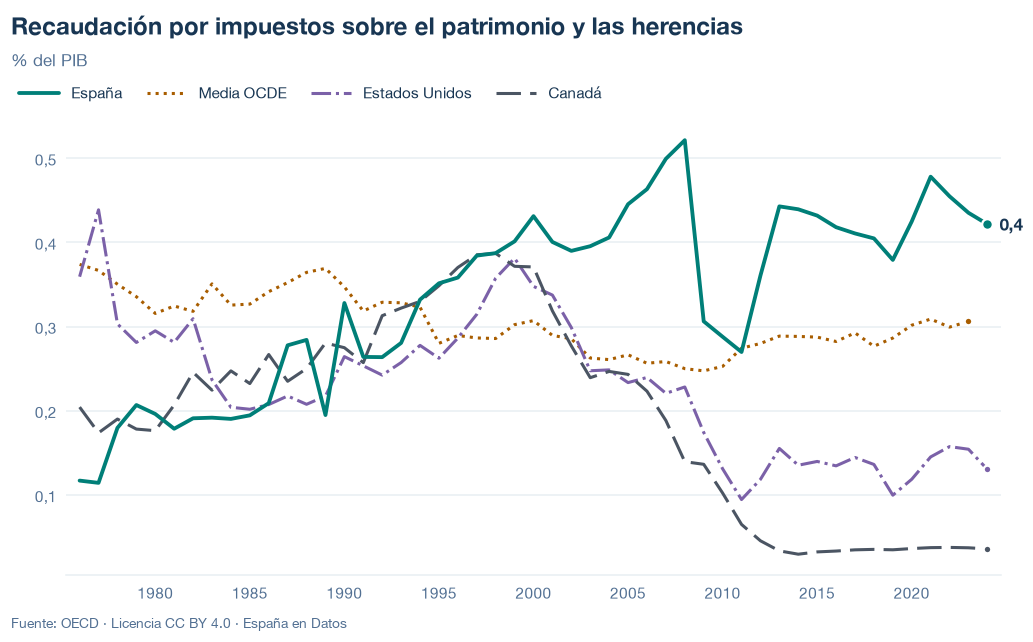

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/impuestos-patrimonio-sucesiones.json y data/impuestos-patrimonio-sucesiones.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0`, categorías `T_4200`, `T_4300` y `T_4220` (España, EE. UU., Canadá y media OCDE), y tabla nacional de España `OECD.CTP.TPS,DSD_REV_OECD@DF_REVESP,2.0` (desglose de la categoría 4200, comprobación).
- Eurostat, `gov_10a_taxag` (`D59A`, `D91A`) y `nama_10_gdp` (`B1GQ`), consultados para la UE-27 y para comparar las fuentes.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.